# Notebook 07 — Exploratory Data Analysis (EDA)

## Objective
Explore IPL player-match performance, identify statistical patterns,
understand distributions, and generate insights for machine learning.

## Analysis sections
1. Dataset overview and data quality
2. Batting performance analysis
3. Bowling performance analysis
4. Player consistency and performance trends
5. Season-wise performance
6. Team-wise comparisons
7. Venue-wise performance
8. Correlation and feature relationships
9. Outlier analysis
10. EDA findings and modelling recommendations

In [11]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Display configuration
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.grid"] = True

print("Libraries imported successfully.")

Libraries imported successfully.


In [12]:
PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PLAYER_MATCH_DIR = PROCESSED_DIR / "player_match"
FEATURE_DIR = PROCESSED_DIR / "features"

print("Project root:", PROJECT_ROOT)
print("Player-match directory:", PLAYER_MATCH_DIR)
print("Feature directory:", FEATURE_DIR)

assert PLAYER_MATCH_DIR.is_dir()
assert FEATURE_DIR.is_dir()

print("\nDIRECTORY VALIDATION: PASS")

Project root: D:\Git\Personal\ipl-player-performance-v2
Player-match directory: D:\Git\Personal\ipl-player-performance-v2\data\processed\player_match
Feature directory: D:\Git\Personal\ipl-player-performance-v2\data\processed\features

DIRECTORY VALIDATION: PASS


In [13]:
files = {
    "batting": PLAYER_MATCH_DIR / "batting_player_match_regular.csv",
    "bowling": PLAYER_MATCH_DIR / "bowling_player_match_regular.csv",
    "batting_features": FEATURE_DIR / "batting_next_match_features.csv",
    "bowling_features": FEATURE_DIR / "bowling_next_match_features.csv",
}

for name, path in files.items():
    print(f"{name}: {path.exists()}")

assert all(path.is_file() for path in files.values())

batting = pd.read_csv(
    files["batting"],
    dtype={"match_id": "string"},
    low_memory=False
)

bowling = pd.read_csv(
    files["bowling"],
    dtype={"match_id": "string"},
    low_memory=False
)

batting_features = pd.read_csv(
    files["batting_features"],
    dtype={"match_id": "string"},
    low_memory=False
)

bowling_features = pd.read_csv(
    files["bowling_features"],
    dtype={"match_id": "string"},
    low_memory=False
)

for df in [batting, bowling, batting_features, bowling_features]:
    df["date"] = pd.to_datetime(df["date"], errors="coerce")

print("\nALL DATASETS LOADED SUCCESSFULLY")

batting: True
bowling: True
batting_features: True
bowling_features: True

ALL DATASETS LOADED SUCCESSFULLY


In [14]:
datasets = {
    "Batting Player-Match": batting,
    "Bowling Player-Match": bowling,
    "Batting Next-Match Features": batting_features,
    "Bowling Next-Match Features": bowling_features,
}

overview = pd.DataFrame([
    {
        "dataset": name,
        "rows": df.shape[0],
        "columns": df.shape[1],
        "missing_cells": int(df.isna().sum().sum()),
        "duplicate_rows": int(df.duplicated().sum())
    }
    for name, df in datasets.items()
])

display(overview)

,dataset,rows,columns,missing_cells,duplicate_rows
0,Batting Player-Match,18822,17,4226,0
1,Bowling Player-Match,14700,16,12503,0
2,Batting Next-Match Features,18822,56,32432,0
3,Bowling Next-Match Features,14700,43,27507,0


In [15]:
assert not batting.duplicated(["match_id", "player"]).any()
assert not bowling.duplicated(["match_id", "player"]).any()

assert batting["date"].notna().all()
assert bowling["date"].notna().all()

assert batting["player"].notna().all()
assert bowling["player"].notna().all()

print("Batting player-match validation: PASS")
print("Bowling player-match validation: PASS")

print("\nEDA INPUT VALIDATION: PASS")

Batting player-match validation: PASS
Bowling player-match validation: PASS

EDA INPUT VALIDATION: PASS


In [16]:
batting_metrics = [
    "runs_scored",
    "balls_faced",
    "fours",
    "sixes",
    "dismissals",
    "strike_rate",
    "batting_average"
]

batting_summary = batting[batting_metrics].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
).T

display(batting_summary)

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
runs_scored,"18,822.00",20.25,21.67,0.00,4.00,13.00,30.00,52.00,66.00,93.00,175.00
balls_faced,"18,822.00",15.18,13.42,0.00,5.00,11.00,22.00,35.00,44.00,56.00,73.00
fours,"18,822.00",1.83,2.32,0.00,0.00,1.00,3.00,5.00,7.00,10.00,19.00
sixes,"18,822.00",0.84,1.43,0.00,0.00,0.00,1.00,3.00,4.00,7.00,17.00
dismissals,"18,822.00",0.78,0.42,0.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
strike_rate,"18,763.00",115.10,69.43,0.00,69.23,113.79,154.55,200.00,228.57,309.86,600.00
batting_average,"14,655.00",19.28,20.08,0.00,4.00,13.00,29.00,49.00,61.00,85.00,141.00


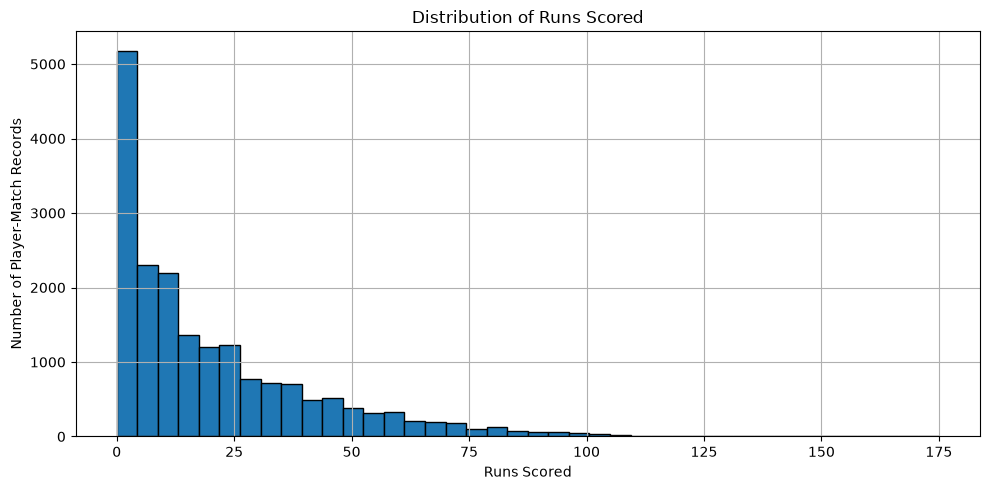

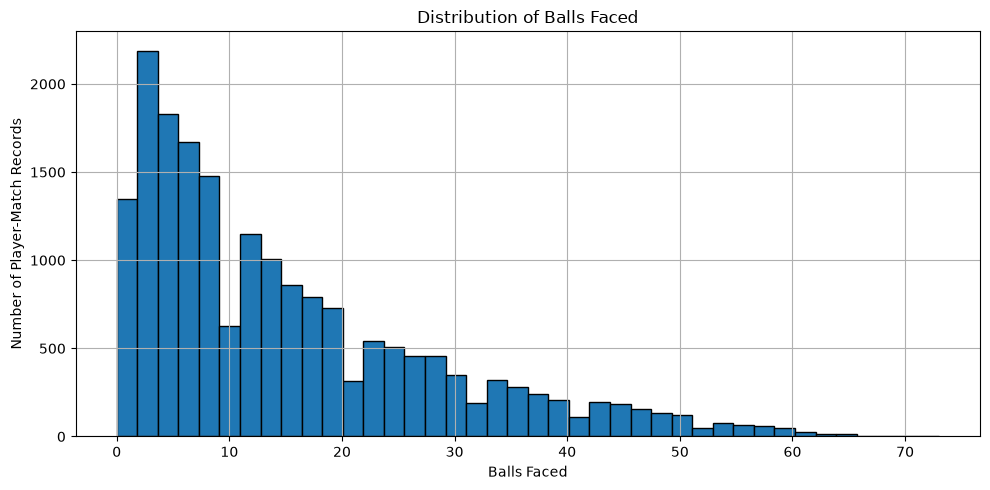

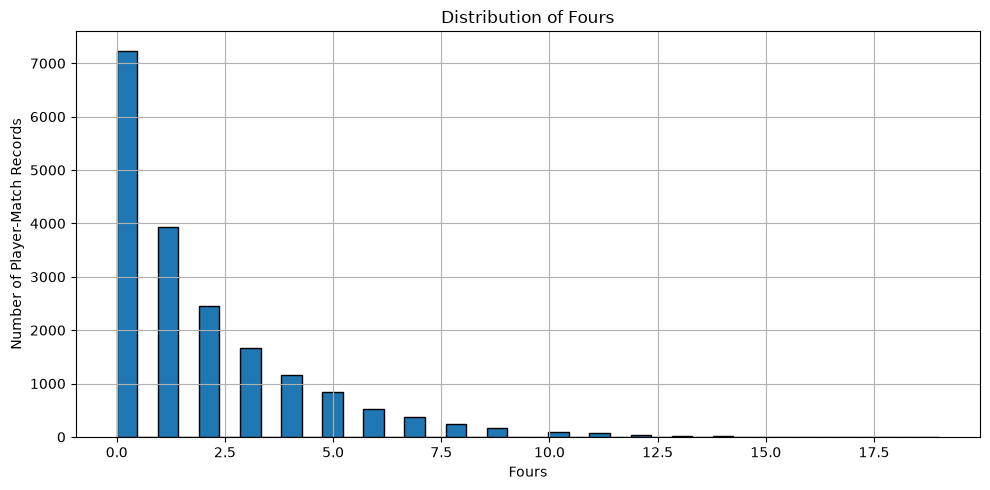

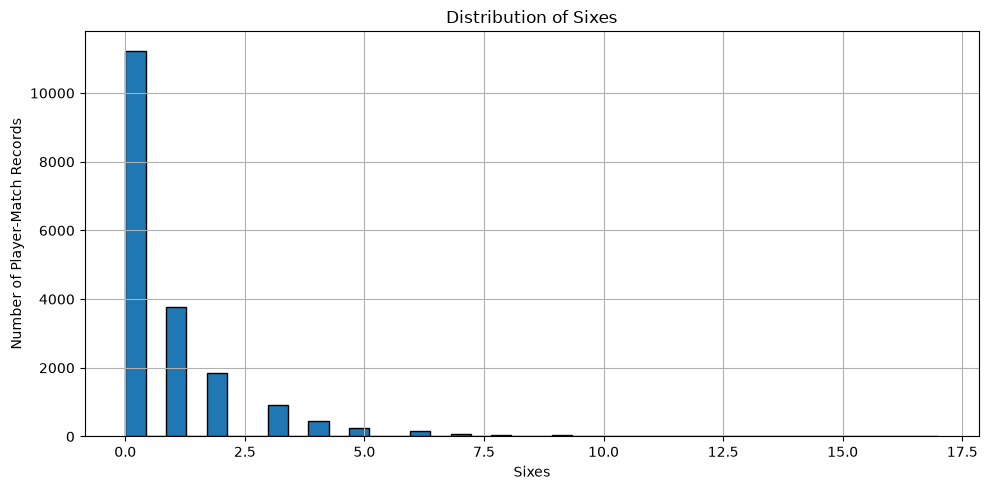

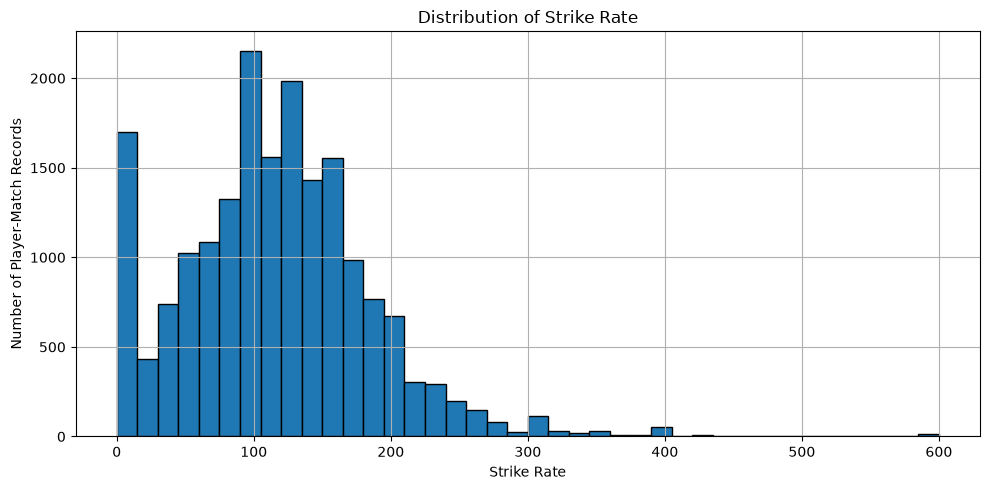

In [17]:
batting_plot_metrics = [
    "runs_scored",
    "balls_faced",
    "fours",
    "sixes",
    "strike_rate"
]

for metric in batting_plot_metrics:
    values = batting[metric].dropna()

    plt.figure(figsize=(10, 5))
    plt.hist(values, bins=40, edgecolor="black")
    plt.title(f"Distribution of {metric.replace('_', ' ').title()}")
    plt.xlabel(metric.replace("_", " ").title())
    plt.ylabel("Number of Player-Match Records")
    plt.tight_layout()
    plt.show()

,runs_category,player_match_count
0,0–9,7955
1,10–19,3711
2,20–29,2364
3,30–49,2677
4,50–99,1990
5,100+,125


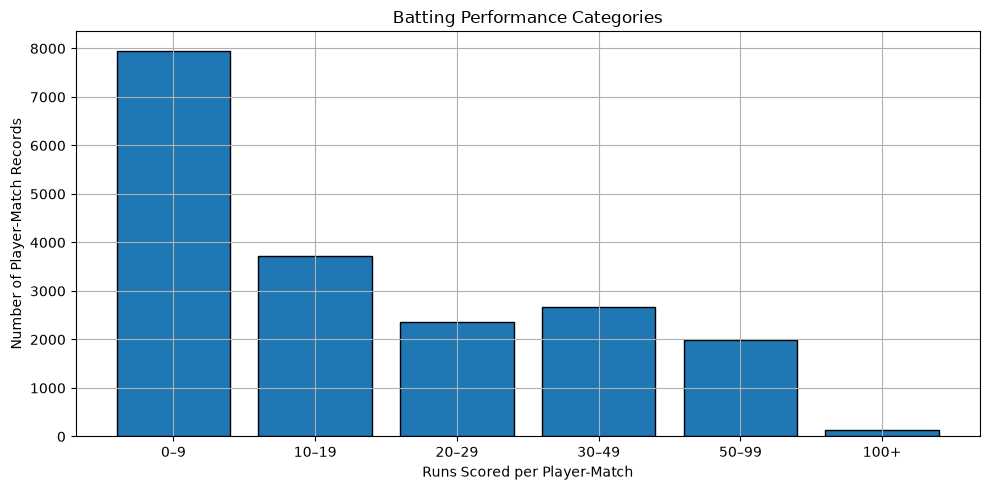

In [18]:
batting["performance_category"] = pd.cut(
    batting["runs_scored"],
    bins=[-1, 9, 19, 29, 49, 99, np.inf],
    labels=[
        "0–9",
        "10–19",
        "20–29",
        "30–49",
        "50–99",
        "100+"
    ]
)

category_counts = (
    batting["performance_category"]
    .value_counts(sort=False)
    .rename_axis("runs_category")
    .reset_index(name="player_match_count")
)

display(category_counts)

plt.figure(figsize=(10, 5))
plt.bar(
    category_counts["runs_category"].astype(str),
    category_counts["player_match_count"],
    edgecolor="black"
)
plt.title("Batting Performance Categories")
plt.xlabel("Runs Scored per Player-Match")
plt.ylabel("Number of Player-Match Records")
plt.tight_layout()
plt.show()

In [19]:
# Inspect the highest strike rates.
strike_rate_outliers = (
    batting[
        ["player", "match_id", "runs_scored", "balls_faced", "strike_rate"]
    ]
    .sort_values("strike_rate", ascending=False)
    .head(20)
)

display(strike_rate_outliers)

,player,match_id,runs_scored,balls_faced,strike_rate
7973,M Shahrukh Khan,1473442,6,1,600.00
3264,N Pooran,1216531,6,1,600.00
16510,R Bhatia,733979,6,1,600.00
13866,DJ Bravo,501271,6,1,600.00
3783,RA Jadeja,1254072,6,1,600.00
8807,Akash Deep,1473499,6,1,600.00
283,Rashid Khan,1082609,6,1,600.00
16946,AP Tare,734041,6,1,600.00
5140,DR Sams,1304090,6,1,600.00
1555,JPR Scantlebury-Searles,1136604,6,1,600.00


In [20]:
# Check whether strike rate is mathematically consistent.
expected_sr = np.where(
    batting["balls_faced"] > 0,
    batting["runs_scored"] / batting["balls_faced"] * 100,
    np.nan
)

sr_difference = np.abs(
    batting["strike_rate"].to_numpy(dtype=float) - expected_sr
)

print("Maximum strike-rate difference:", np.nanmax(sr_difference))
print(
    "Records with difference > 0.01:",
    np.sum(sr_difference > 0.01)
)

Maximum strike-rate difference: 0.0
Records with difference > 0.01: 0


### Strike Rate Outlier Investigation

- Extreme strike rates were observed, reaching 600.
- These observations correspond to short innings, such as 6 runs from 1 ball.
- Strike rate was independently recalculated using:
  (runs_scored / balls_faced) * 100.
- Maximum absolute difference was 0.0.
- No inconsistent records were detected.

Decision:
Retain extreme strike rates because they are mathematically valid
and represent genuine short-innings performance.
No outlier capping or deletion will be applied.

In [21]:
bowling_metrics = [
    "runs_conceded",
    "legal_balls",
    "wickets",
    "overs_bowled",
    "economy_rate",
    "bowling_average",
    "bowling_strike_rate"
]

bowling_summary = bowling[bowling_metrics].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
).T

display(bowling_summary)

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
runs_conceded,"14,700.00",26.82,11.21,0.00,19.00,26.00,34.00,41.00,46.00,55.00,76.00
legal_balls,"14,700.00",19.35,6.13,0.00,18.00,24.00,24.00,24.00,24.00,24.00,25.00
wickets,"14,700.00",0.92,1.00,0.00,0.00,1.00,1.00,2.00,3.00,4.00,6.00
overs_bowled,"14,700.00",3.23,1.02,0.00,3.00,4.00,4.00,4.00,4.00,4.00,4.17
economy_rate,"14,699.00",8.65,3.34,0.00,6.33,8.25,10.33,12.75,14.33,19.00,54.00
bowling_average,"8,449.00",21.38,11.99,0.00,11.50,19.00,30.00,39.00,43.00,52.00,69.00
bowling_strike_rate,"8,449.00",16.12,6.70,1.00,12.00,12.00,24.00,24.00,24.00,24.00,24.00


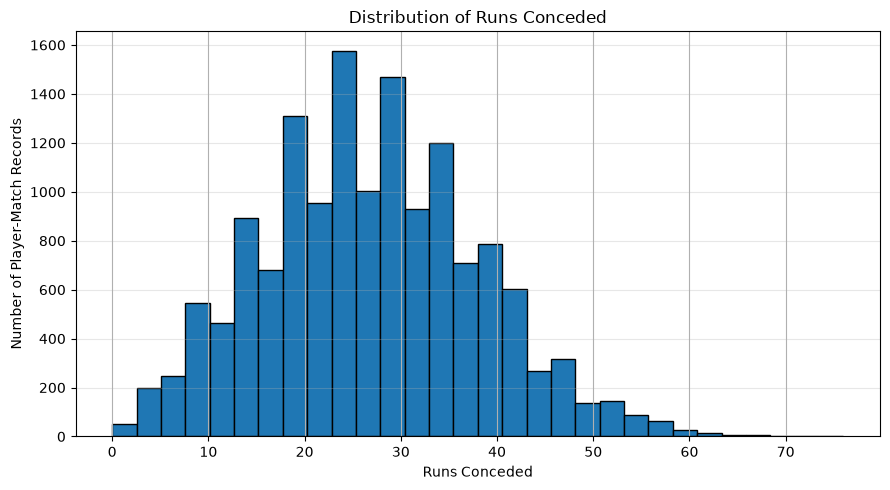

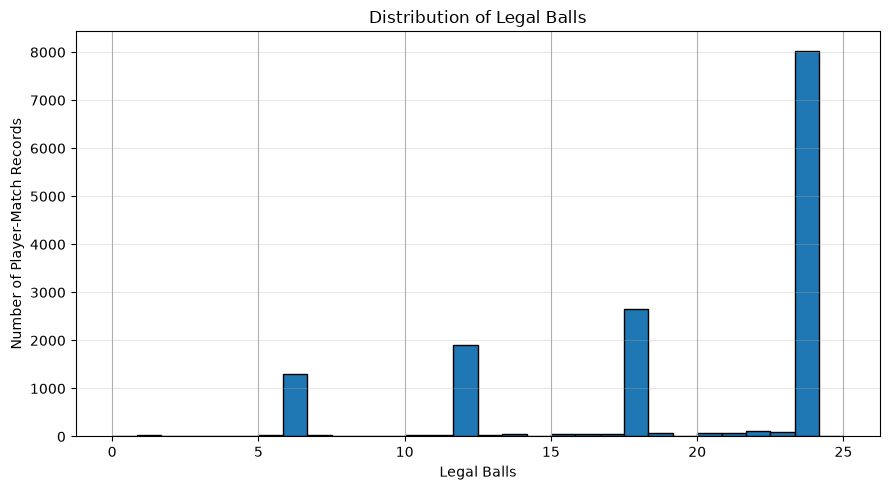

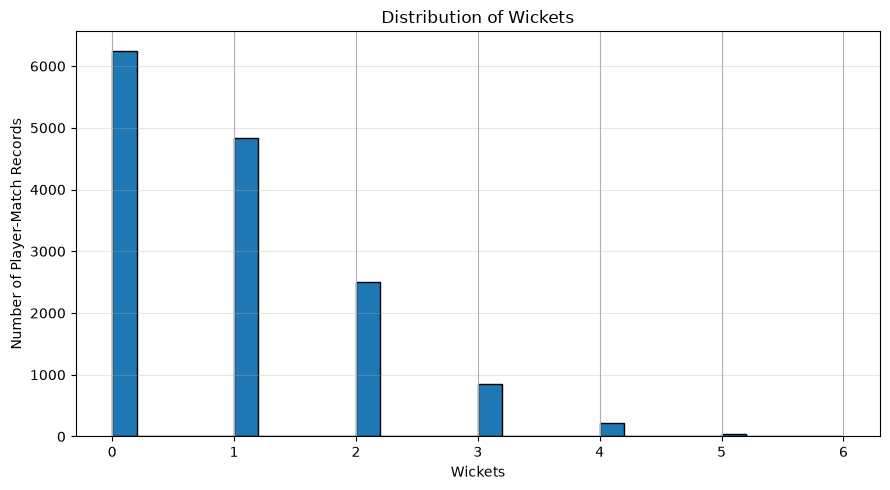

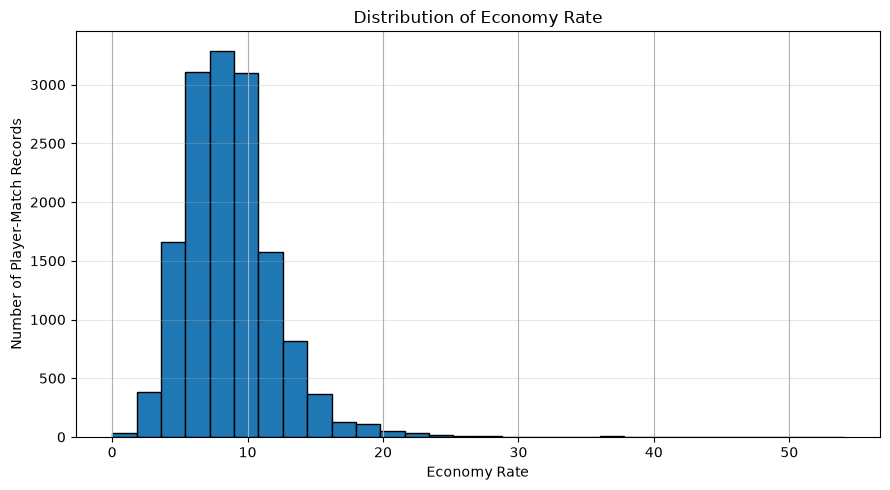

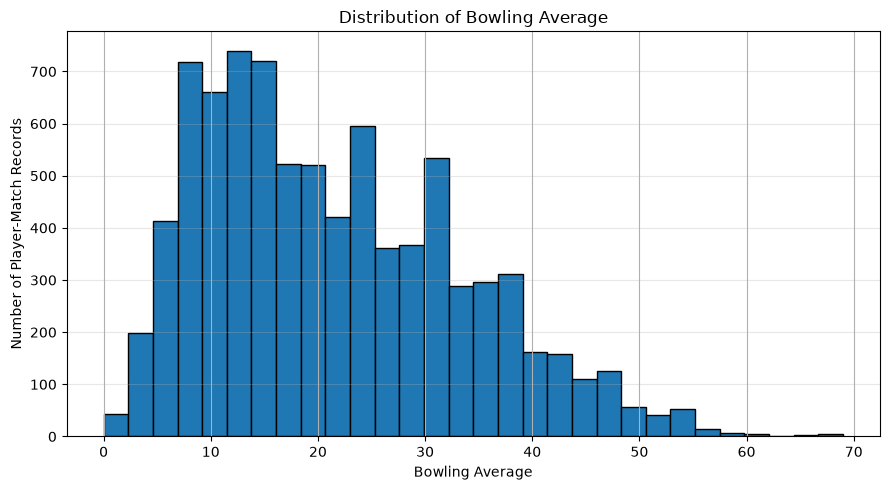

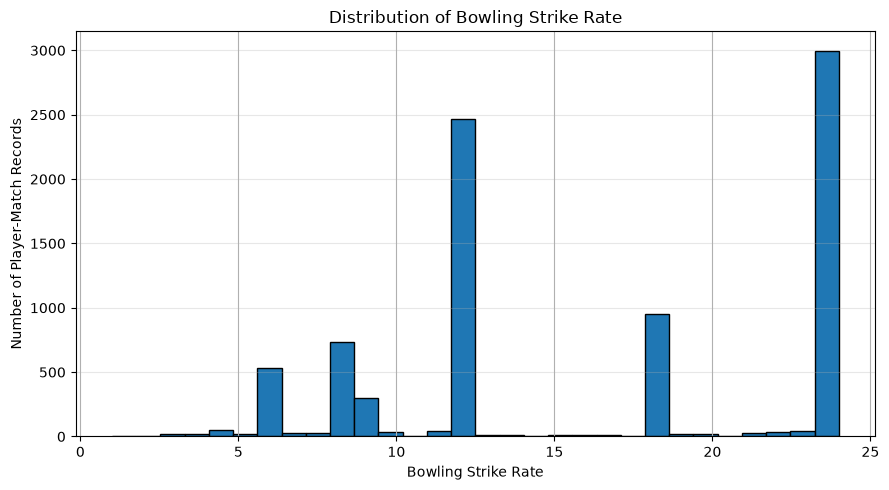

In [22]:
import matplotlib.pyplot as plt

bowling_plot_metrics = [
    "runs_conceded",
    "legal_balls",
    "wickets",
    "economy_rate",
    "bowling_average",
    "bowling_strike_rate"
]

for metric in bowling_plot_metrics:
    plt.figure(figsize=(9, 5))

    plt.hist(
        bowling[metric].dropna(),
        bins=30,
        edgecolor="black"
    )

    plt.title(f"Distribution of {metric.replace('_', ' ').title()}")
    plt.xlabel(metric.replace("_", " ").title())
    plt.ylabel("Number of Player-Match Records")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

In [23]:
# Bowling metric validation

import numpy as np
import pandas as pd

# Recalculate bowling metrics
bowling_check = bowling.copy()

bowling_check["calculated_economy"] = np.where(
    bowling_check["legal_balls"] > 0,
    bowling_check["runs_conceded"] * 6
    / bowling_check["legal_balls"],
    np.nan
)

bowling_check["calculated_average"] = np.where(
    bowling_check["wickets"] > 0,
    bowling_check["runs_conceded"]
    / bowling_check["wickets"],
    np.nan
)

bowling_check["calculated_strike_rate"] = np.where(
    bowling_check["wickets"] > 0,
    bowling_check["legal_balls"]
    / bowling_check["wickets"],
    np.nan
)

# Compare calculated values with stored values
metric_checks = {
    "economy_rate": "calculated_economy",
    "bowling_average": "calculated_average",
    "bowling_strike_rate": "calculated_strike_rate"
}

for original, calculated in metric_checks.items():
    difference = (
        bowling_check[original] - bowling_check[calculated]
    ).abs()

    print(f"\n{original}")
    print("Maximum difference:", difference.max())
    print("Mismatches:", (difference > 0.01).sum())

# Check structural missingness
print("\nMissingness by wicket count:")
display(
    bowling_check.groupby("wickets")[
        ["bowling_average", "bowling_strike_rate"]
    ].agg(["count", "size"])
)

# Inspect extreme economy records
print("\nTop 15 economy-rate records:")

display(
    bowling_check.nlargest(15, "economy_rate")[
        [
            "player",
            "match_id",
            "runs_conceded",
            "legal_balls",
            "wickets",
            "economy_rate"
        ]
    ]
)

print("\nBOWLING METRIC VALIDATION CELL COMPLETED")


economy_rate
Maximum difference: 3.552713678800501e-15
Mismatches: 0

bowling_average
Maximum difference: 0.0
Mismatches: 0

bowling_strike_rate
Maximum difference: 0.0
Mismatches: 0

Missingness by wicket count:


bowling_average       bowling_strike_rate      
                  count  size               count  size
wickets                                                
0                     0  6251                   0  6251
1                  4841  4841                4841  4841
2                  2503  2503                2503  2503
3                   848   848                 848   848
4                   219   219                 219   219
5                    35    35                  35    35
6                     3     3                   3     3


Top 15 economy-rate records:


,player,match_id,runs_conceded,legal_balls,wickets,economy_rate
6405,RA Jadeja,1473462,9,1,0,54.00
7578,AK Markram,1529296,14,2,0,42.00
915,TK Curran,1136578,6,1,0,36.00
3650,YBK Jaiswal,1304059,6,1,0,36.00
7030,Abdul Samad,1527678,6,1,0,36.00
7712,Shahbaz Ahmed,1529307,6,1,0,36.00
7301,AK Markram,1529272,32,6,0,32.00
8266,CK Kapugedera,336018,26,5,0,31.20
6655,Karim Janat,1473484,30,6,0,30.00
11317,AL Menaria,548349,10,2,0,30.00



BOWLING METRIC VALIDATION CELL COMPLETED


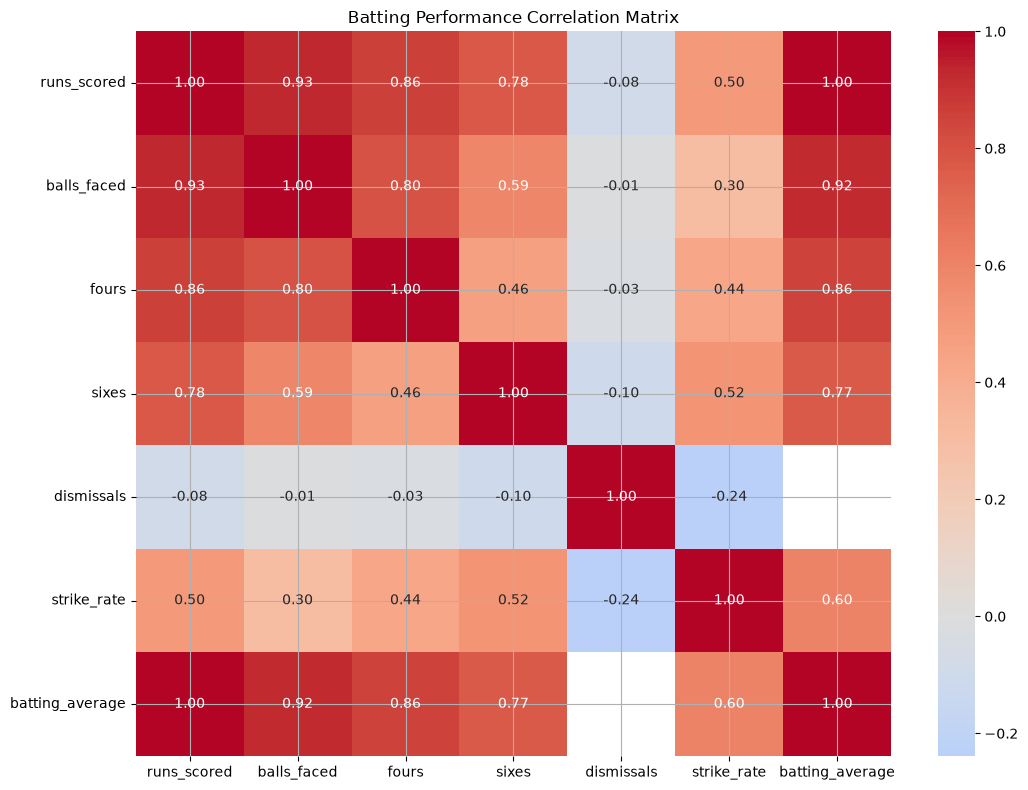

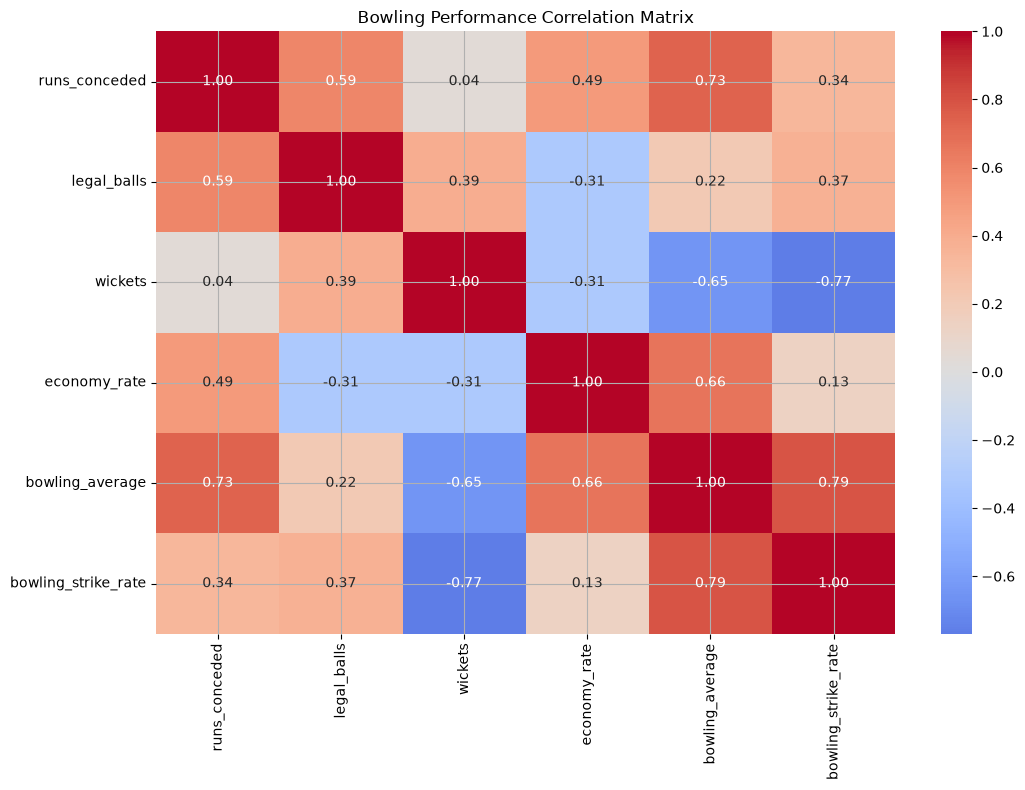

BATTING CORRELATION MATRIX


,runs_scored,balls_faced,fours,sixes,dismissals,strike_rate,batting_average
runs_scored,1.00,0.93,0.86,0.78,-0.08,0.50,1.00
balls_faced,0.93,1.00,0.80,0.59,-0.01,0.30,0.93
fours,0.86,0.80,1.00,0.46,-0.03,0.44,0.86
sixes,0.78,0.59,0.46,1.00,-0.10,0.52,0.77
dismissals,-0.08,-0.01,-0.03,-0.10,1.00,-0.24,NaN
strike_rate,0.50,0.30,0.44,0.52,-0.24,1.00,0.60
batting_average,1.00,0.93,0.86,0.77,NaN,0.60,1.00


BOWLING CORRELATION MATRIX


,runs_conceded,legal_balls,wickets,economy_rate,bowling_average,bowling_strike_rate
runs_conceded,1.00,0.59,0.04,0.49,0.73,0.34
legal_balls,0.59,1.00,0.39,-0.31,0.22,0.37
wickets,0.04,0.39,1.00,-0.31,-0.65,-0.77
economy_rate,0.49,-0.31,-0.31,1.00,0.66,0.13
bowling_average,0.73,0.22,-0.65,0.66,1.00,0.79
bowling_strike_rate,0.34,0.37,-0.77,0.13,0.79,1.00


In [24]:
# Batting and bowling correlation analysis

import matplotlib.pyplot as plt
import seaborn as sns

batting_metrics = [
    "runs_scored",
    "balls_faced",
    "fours",
    "sixes",
    "dismissals",
    "strike_rate",
    "batting_average"
]

bowling_metrics = [
    "runs_conceded",
    "legal_balls",
    "wickets",
    "economy_rate",
    "bowling_average",
    "bowling_strike_rate"
]

# Batting correlation
batting_corr = batting[batting_metrics].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(
    batting_corr,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)
plt.title("Batting Performance Correlation Matrix")
plt.tight_layout()
plt.show()

# Bowling correlation
bowling_corr = bowling[bowling_metrics].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(
    bowling_corr,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)
plt.title("Bowling Performance Correlation Matrix")
plt.tight_layout()
plt.show()

print("BATTING CORRELATION MATRIX")
display(batting_corr.round(3))

print("BOWLING CORRELATION MATRIX")
display(bowling_corr.round(3))

In [25]:
# High-correlation feature audit

def get_high_correlations(corr_matrix, threshold=0.75):

    upper_triangle = corr_matrix.where(
        np.triu(
            np.ones(corr_matrix.shape),
            k=1
        ).astype(bool)
    )

    pairs = (
        upper_triangle
        .stack()
        .reset_index()
    )

    pairs.columns = [
        "feature_1",
        "feature_2",
        "correlation"
    ]

    pairs["absolute_correlation"] = (
        pairs["correlation"].abs()
    )

    return (
        pairs[
            pairs["absolute_correlation"] >= threshold
        ]
        .sort_values(
            "absolute_correlation",
            ascending=False
        )
        .reset_index(drop=True)
    )


print("BATTING HIGH CORRELATIONS")

batting_high_corr = get_high_correlations(
    batting_corr,
    threshold=0.75
)

display(batting_high_corr)


print("\nBOWLING HIGH CORRELATIONS")

bowling_high_corr = get_high_correlations(
    bowling_corr,
    threshold=0.75
)

display(bowling_high_corr)


print("\nBATTING AVERAGE INVESTIGATION")

display(
    batting[
        [
            "runs_scored",
            "dismissals",
            "batting_average"
        ]
    ].describe()
)

print(
    "\nCorrelation between runs and batting average:",
    batting["runs_scored"].corr(
        batting["batting_average"]
    )
)

print("\nFEATURE RELATIONSHIP AUDIT COMPLETED")

BATTING HIGH CORRELATIONS


,feature_1,feature_2,correlation,absolute_correlation
0,runs_scored,batting_average,1.00,1.00
1,runs_scored,balls_faced,0.93,0.93
2,balls_faced,batting_average,0.92,0.92
3,runs_scored,fours,0.86,0.86
4,fours,batting_average,0.86,0.86
5,balls_faced,fours,0.80,0.80
6,runs_scored,sixes,0.78,0.78
7,sixes,batting_average,0.77,0.77



BOWLING HIGH CORRELATIONS


,feature_1,feature_2,correlation,absolute_correlation
0,bowling_average,bowling_strike_rate,0.79,0.79
1,wickets,bowling_strike_rate,-0.77,0.77



BATTING AVERAGE INVESTIGATION


,runs_scored,dismissals,batting_average
count,"18,822.00","18,822.00","14,655.00"
mean,20.25,0.78,19.28
std,21.67,0.42,20.08
min,0.00,0.00,0.00
25%,4.00,1.00,4.00
50%,13.00,1.00,13.00
75%,30.00,1.00,29.00
max,175.00,1.00,141.00



Correlation between runs and batting average: 1.0

FEATURE RELATIONSHIP AUDIT COMPLETED


In [26]:
# Investigate batting average calculation

investigation = batting[
    [
        "player",
        "match_id",
        "runs_scored",
        "dismissals",
        "batting_average"
    ]
].copy()

investigation["runs_minus_average"] = (
    investigation["runs_scored"]
    - investigation["batting_average"]
)

print("BATTTING AVERAGE INVESTIGATION")

print("\nColumn equality:")
print(
    "Runs equal batting average:",
    np.allclose(
        investigation["runs_scored"],
        investigation["batting_average"],
        equal_nan=True
    )
)

print("\nDifference statistics:")
display(
    investigation["runs_minus_average"].describe()
)

print("\nRecords with non-zero differences:")
display(
    investigation[
        investigation["runs_minus_average"].abs() > 0.000001
    ].head(15)
)

print("\nSample records:")
display(investigation.head(15))

print("\nDismissal distribution:")
display(
    investigation["dismissals"].value_counts().sort_index()
)

print("\nBATTTING AVERAGE INVESTIGATION COMPLETED")

BATTTING AVERAGE INVESTIGATION

Column equality:
Runs equal batting average: False

Difference statistics:


count   14,655.00
mean         0.00
std          0.00
min          0.00
25%          0.00
50%          0.00
75%          0.00
max          0.00
Name: runs_minus_average, dtype: float64


Records with non-zero differences:


,player,match_id,runs_scored,dismissals,batting_average,runs_minus_average



Sample records:


,player,match_id,runs_scored,dismissals,batting_average,runs_minus_average
0,A Choudhary,1082591,6,0,NaN,NaN
1,BCJ Cutting,1082591,16,0,NaN,NaN
2,CH Gayle,1082591,32,1,32.00,0.00
3,DA Warner,1082591,14,1,14.00,0.00
4,DJ Hooda,1082591,16,0,NaN,NaN
5,KM Jadhav,1082591,31,1,31.00,0.00
6,MC Henriques,1082591,52,1,52.00,0.00
7,Mandeep Singh,1082591,24,1,24.00,0.00
8,S Aravind,1082591,0,1,0.00,0.00
9,S Dhawan,1082591,40,1,40.00,0.00



Dismissal distribution:


dismissals
0     4167
1    14655
Name: count, dtype: int64


BATTTING AVERAGE INVESTIGATION COMPLETED


In [27]:
# Batting average validation

dismissed = batting["dismissals"] > 0
not_dismissed = batting["dismissals"] == 0

assert np.allclose(
    batting.loc[dismissed, "batting_average"],
    batting.loc[dismissed, "runs_scored"],
    equal_nan=True
)

assert batting.loc[not_dismissed, "batting_average"].isna().all()

print("Dismissed records:", dismissed.sum())
print("Not-dismissed records:", not_dismissed.sum())
print("Batting average equals runs for dismissed records: PASS")
print("Batting average is undefined for not-dismissed records: PASS")
print("BATTING AVERAGE VALIDATION: PASS")

Dismissed records: 14655
Not-dismissed records: 4167
Batting average equals runs for dismissed records: PASS
Batting average is undefined for not-dismissed records: PASS
BATTING AVERAGE VALIDATION: PASS


# EDA Conclusions and Business Insights

## 1. Batting Performance
- Runs scored and balls faced have a strong positive relationship.
- Fours and sixes contribute substantially to scoring patterns.
- Batting performance distributions are right-skewed.
- Strike rate contains extreme values, particularly for low-ball innings.

## 2. Bowling Performance
- Runs conceded and legal balls have a positive relationship.
- Wickets are negatively associated with bowling average and bowling strike rate.
- Economy rate and bowling average show substantial variation across players.

## 3. Feature Relationships
- Strong correlations exist among several batting metrics.
- Bowling average and bowling strike rate are also correlated.
- Correlation does not establish causation.

## 4. Batting Average Investigation
- 14,655 records have one dismissal.
- 4,167 records have zero dismissals.
- For dismissed player-match records, batting average equals runs scored.
- For not-dismissed records, batting average is undefined.
- The perfect correlation is explained by the player-match aggregation.

## 5. Modeling Considerations
- Use chronological train/test splitting.
- Use historical features only.
- Exclude current-match information from predictors.
- Investigate correlated predictors before model selection.
- Evaluate batting and bowling predictions separately.

## 6. EDA Outcome
The datasets have passed the current structural and metric validation checks.
They are ready for the next stage after final feature and leakage audits.